In [21]:
import pandas as pd
url = "https://raw.githubusercontent.com/vbalagovic/cars-dataset/main/motorcycle_data_sample.csv"
df = pd.read_csv(url)
df.head()

,id,brand,model,year,variant_name,trim,category,subcategory,engine_type,cubic_capacity_cc,cylinders,cylinder_config,aspiration,power_kw,power_hp,torque_nm,transmission_type,gears,drive_type,fuel_type,fuel_consumption_combined,co2_emissions_gkm,top_speed_kmh,acceleration_0_100_s,curb_weight_kg,seat_height_mm,fuel_tank_capacity_l,length_mm,width_mm,height_mm,wheelbase_mm,front_suspension,rear_suspension,front_brake,rear_brake,abs_type,traction_control,riding_modes,price_eur,features,is_electric,is_scooter,data_source,created_at
0,466,Aprilia,RS-GP,2021.0,Aprilia motorcycles Aprilia RS-GP 2021,NaN,sport,NaN,"V4, four-stroke",999.0,NaN,V4,naturally aspirated,186.1,255.0,115.0,manual,6.0,NaN,gasoline,NaN,NaN,350.0,NaN,160.0,840.0,22.0,2040.0,NaN,NaN,1420.0,NaN,NaN,Double disc. Brembo M4 Floating stainless stee...,Single disc. Brembo calliper with two Ø 32 mm ...,NaN,NaN,NaN,NaN,"[""Starter: Electric"", ""Cooling system: Liquid""...",False,False,bikez,2026-04-04T11:32:06.754747
1,343,BMW,450 Sports Enduro,2008.0,BMW BMW 450 Sports Enduro 2008,NaN,enduro,NaN,"Single cylinder, four-stroke",449.0,NaN,Single,naturally aspirated,36.2,49.6,48.0,manual,5.0,NaN,gasoline,NaN,NaN,NaN,NaN,120.0,911.0,8.5,NaN,NaN,NaN,NaN,NaN,NaN,Single disc. Bremo,Single disc. Bremo,NaN,NaN,NaN,NaN,"[""Frame type: Lightweight stainless steel tube...",False,False,bikez,2026-04-04T11:32:06.754747
2,352,BMW,K1200R,2007.0,BMW BMW K1200R 2007,NaN,naked,NaN,"In-line four, four-stroke",1157.0,NaN,Inline-4,naturally aspirated,119.0,163.0,127.0,manual,6.0,NaN,gasoline,5.5,128.0,NaN,NaN,211.0,820.0,19.0,2228.0,NaN,NaN,1580.0,NaN,NaN,Single disc,Single disc,NaN,NaN,NaN,NaN,"[""Starter: Electric"", ""Cooling system: Liquid""...",False,False,bikez,2026-04-04T11:32:06.754747
3,354,BMW,R 1200 Independent,2001.0,BMW BMW R 1200 Independent 2001,NaN,cruiser,NaN,"Two cylinder boxer, four-stroke",1170.0,NaN,Boxer,naturally aspirated,44.5,61.0,98.0,manual,5.0,NaN,gasoline,NaN,NaN,172.0,NaN,256.0,740.0,17.0,NaN,NaN,NaN,1650.0,NaN,NaN,Dual disc,Single disc,NaN,NaN,NaN,NaN,"[""Starter: Electric"", ""Cooling system: Air"", ""...",False,False,bikez,2026-04-04T11:32:06.754747
4,397,Ducati,Monster M750,1999.0,Ducati Ducati Monster M750 1999,NaN,naked,NaN,"V2, four-stroke",748.0,NaN,NaN,naturally aspirated,46.7,64.0,62.0,manual,5.0,NaN,gasoline,6.8,158.0,195.0,NaN,192.0,770.0,18.0,NaN,NaN,NaN,1430.0,NaN,NaN,Dual disc,Single disc,NaN,NaN,NaN,NaN,"[""Starter: Electric"", ""Cooling system: Oil & a...",False,False,bikez,2026-04-04T11:32:06.754747


In [22]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30 entries, 0 to 29
Data columns (total 44 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   id                         30 non-null     int64  
 1   brand                      30 non-null     object 
 2   model                      30 non-null     object 
 3   year                       26 non-null     float64
 4   variant_name               30 non-null     object 
 5   trim                       0 non-null      float64
 6   category                   30 non-null     object 
 7   subcategory                7 non-null      object 
 8   engine_type                28 non-null     object 
 9   cubic_capacity_cc          29 non-null     float64
 10  cylinders                  0 non-null      float64
 11  cylinder_config            21 non-null     object 
 12  aspiration                 30 non-null     object 
 13  power_kw                   27 non-null     float64
 

In [23]:
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline 

<Axes: xlabel='cubic_capacity_cc', ylabel='power_hp'>

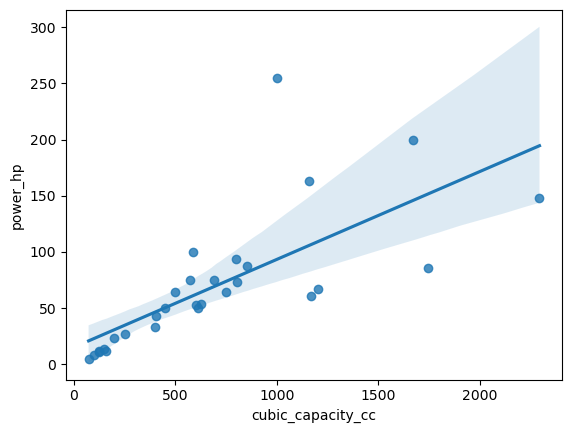

In [24]:
sns.regplot(x="cubic_capacity_cc", y="power_hp", data=df)

In [46]:
# Create a model
from sklearn.linear_model import LinearRegression
import numpy as np

lm = LinearRegression()

# We have to repalce N/A for some valueabs
mean_power_hp = df["power_hp"].mean()
mean_cubic_cc = df["cubic_capacity_cc"].mean()

df["power_hp"] = df["power_hp"].replace(np.nan, mean_power_hp)
df["cubic_capacity_cc"] = df["cubic_capacity_cc"].replace(np.nan, mean_cubic_cc)

# Predictor variable is cubica_capacity_cc and target model is power_hp
x = df[["cubic_capacity_cc"]]
y = df[["power_hp"]]

# Train the model
lm.fit(x,y)

# Now we create a prediction using a value
yhat = lm.predict(df[["cubic_capacity_cc"]])

LinearRegression()


<Axes: xlabel='power_hp', ylabel='cubic_capacity_cc'>

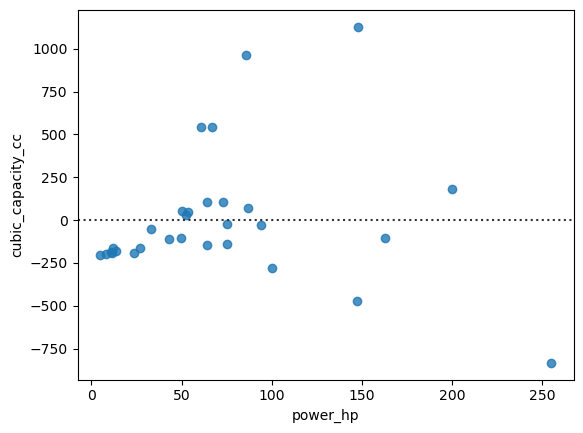

In [37]:
# Create a residual plot
sns.residplot(x="power_hp", y="cubic_capacity_cc", data=df)

In [47]:
m = lm.coef_[0][0]
b = lm.intercept_[0]

print(f"Modelo: power_hp = {m} * cubic_capacity_cc + {b}")

Modelo: power_hp = 0.0782020009020735 * cubic_capacity_cc + 17.701481123513688


<Axes: xlabel='power_hp', ylabel='Density'>

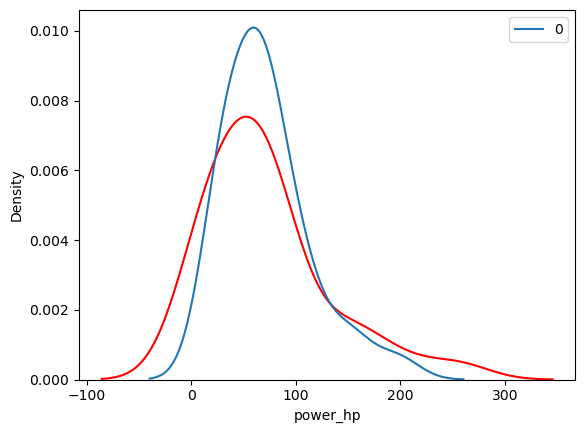

In [45]:
ax1 = sns.kdeplot(data=df['power_hp'], color="r", label = "potencia real")
sns.kdeplot(data = yhat, color="b", label="predicted values", ax=ax1, warn_singular=False)

In [51]:
# Calculate mean square eIOError
from sklearn.metrics import mean_squared_error

mean_squared_error(df['power_hp'], yhat)

1761.7300675475556

In [52]:
df["power_hp"].describe()

count     30.000000
mean      71.763333
std       59.600165
min        4.900000
25%       28.500000
50%       62.500000
75%       86.750000
max      255.000000
Name: power_hp, dtype: float64

In [54]:
print(lm.score(x,y))

0.48694053706853235
